In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df=pd.read_csv("/content/sales_transactions_regression.csv")
df

,transaction_id,region,product_id,product_id.1,sales_amount,date,units_sold,unit_price,discount_pct,store_id,product_id.2,product_id.3
0,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
1,T50001,East,394.0,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3,394.0,394.0
2,T50002,West,446.0,446.0,323.4660,2024-01-03,4.0,92.95,NaN,S2,446.0,446.0
3,T50003,South,136.0,136.0,3439.5648,2024-01-04,8.0,438.72,NaN,S4,136.0,136.0
4,T50004,South,287.0,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4,287.0,287.0
...,...,...,...,...,...,...,...,...,...,...,...,...
255,T50027,North,141.0,141.0,1831.4256,2024-01-28,4.0,497.67,0.08,S2,141.0,141.0
256,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
257,T50125,SOUTH,115.0,115.0,426.1950,2024-05-05,2.0,387.45,0.45,S1,115.0,115.0
258,T50190,East,NaN,NaN,965.5788,2024-07-09,4.0,271.23,0.11,S2,NaN,NaN


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  249 non-null    object 
 1   region          245 non-null    object 
 2   product_id      239 non-null    float64
 3   product_id.1    239 non-null    float64
 4   sales_amount    249 non-null    float64
 5   date            248 non-null    object 
 6   units_sold      241 non-null    float64
 7   unit_price      239 non-null    float64
 8   discount_pct    244 non-null    float64
 9   store_id        249 non-null    object 
 10  product_id.2    239 non-null    float64
 11  product_id.3    239 non-null    float64
dtypes: float64(8), object(4)
memory usage: 24.5+ KB


In [ ]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
255,True
256,True
257,True
258,True


In [ ]:
df["unit_price"].fillna(df["unit_price"].median(), inplace=True)

/tmp/ipykernel_1337/259385082.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["unit_price"].fillna(df["unit_price"].median(), inplace=True)


Handling Missing Values

In [ ]:
df["unit_price"].fillna(method="ffill",inplace=True)
df

/tmp/ipykernel_1337/101751436.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["unit_price"].fillna(method="ffill",inplace=True)
/tmp/ipykernel_1337/101751436.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["unit_price"].fillna(method="ffill",inplace=True)


,transaction_id,region,product_id,product_id.1,sales_amount,date,units_sold,unit_price,discount_pct,store_id,product_id.2,product_id.3
0,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
1,T50001,East,394.0,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3,394.0,394.0
2,T50002,West,446.0,446.0,323.4660,2024-01-03,4.0,92.95,NaN,S2,446.0,446.0
3,T50003,South,136.0,136.0,3439.5648,2024-01-04,8.0,438.72,NaN,S4,136.0,136.0
4,T50004,South,287.0,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4,287.0,287.0
...,...,...,...,...,...,...,...,...,...,...,...,...
255,T50027,North,141.0,141.0,1831.4256,2024-01-28,4.0,497.67,0.08,S2,141.0,141.0
256,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
257,T50125,SOUTH,115.0,115.0,426.1950,2024-05-05,2.0,387.45,0.45,S1,115.0,115.0
258,T50190,East,NaN,NaN,965.5788,2024-07-09,4.0,271.23,0.11,S2,NaN,NaN


In [ ]:
df["units_sold"].fillna(method="ffill",inplace=True)
df

/tmp/ipykernel_1337/4146504801.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["units_sold"].fillna(method="ffill",inplace=True)
/tmp/ipykernel_1337/4146504801.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["units_sold"].fillna(method="ffill",inplace=True)


,transaction_id,region,product_id,product_id.1,sales_amount,date,units_sold,unit_price,discount_pct,store_id,product_id.2,product_id.3
0,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
1,T50001,East,394.0,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3,394.0,394.0
2,T50002,West,446.0,446.0,323.4660,2024-01-03,4.0,92.95,NaN,S2,446.0,446.0
3,T50003,South,136.0,136.0,3439.5648,2024-01-04,8.0,438.72,NaN,S4,136.0,136.0
4,T50004,South,287.0,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4,287.0,287.0
...,...,...,...,...,...,...,...,...,...,...,...,...
255,T50027,North,141.0,141.0,1831.4256,2024-01-28,4.0,497.67,0.08,S2,141.0,141.0
256,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
257,T50125,SOUTH,115.0,115.0,426.1950,2024-05-05,2.0,387.45,0.45,S1,115.0,115.0
258,T50190,East,NaN,NaN,965.5788,2024-07-09,4.0,271.23,0.11,S2,NaN,NaN


In [ ]:
df["discount_pct"].unique()

array([0.31, 0.18,  nan, 0.35, 0.19, 0.41, 0.39, 0.44, 0.3 , 0.12, 0.28,
       0.  , 0.16, 0.1 , 0.33, 0.07, 0.15, 0.17, 0.02, 0.06, 0.08, 0.42,
       0.24, 0.01, 0.49, 0.47, 0.13, 0.29, 0.27, 0.2 , 0.09, 0.26, 0.23,
       0.37, 0.22, 0.25, 0.34, 0.43, 0.48, 0.4 , 0.04, 0.05, 0.21, 0.03,
       0.46, 0.45, 0.32, 0.11, 0.36, 0.38])

In [ ]:
df["discount_pct"].fillna(method="ffill",inplace=True)
df

/tmp/ipykernel_1337/3085442550.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df["discount_pct"].fillna(method="ffill",inplace=True)
/tmp/ipykernel_1337/3085442550.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df["discount_pct"].fillna(method="ffill",inplace=True)


,transaction_id,region,product_id,product_id.1,sales_amount,date,units_sold,unit_price,discount_pct,store_id,product_id.2,product_id.3
0,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
1,T50001,East,394.0,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3,394.0,394.0
2,T50002,West,446.0,446.0,323.4660,2024-01-03,4.0,92.95,0.18,S2,446.0,446.0
3,T50003,South,136.0,136.0,3439.5648,2024-01-04,8.0,438.72,0.18,S4,136.0,136.0
4,T50004,South,287.0,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4,287.0,287.0
...,...,...,...,...,...,...,...,...,...,...,...,...
255,T50027,North,141.0,141.0,1831.4256,2024-01-28,4.0,497.67,0.08,S2,141.0,141.0
256,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
257,T50125,SOUTH,115.0,115.0,426.1950,2024-05-05,2.0,387.45,0.45,S1,115.0,115.0
258,T50190,East,NaN,NaN,965.5788,2024-07-09,4.0,271.23,0.11,S2,NaN,NaN


In [ ]:
df.isnull()

,transaction_id,region,product_id,product_id.1,sales_amount,date,units_sold,unit_price,discount_pct,store_id,product_id.2,product_id.3
0,False,False,False,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...
255,False,False,False,False,False,False,False,False,False,False,False,False
256,False,False,False,False,False,False,False,False,False,False,False,False
257,False,False,False,False,False,False,False,False,False,False,False,False
258,False,False,True,True,False,False,False,False,False,False,True,True


In [ ]:
df.ffill(inplace=True)
df

,transaction_id,region,product_id,product_id.1,sales_amount,date,units_sold,unit_price,discount_pct,store_id,product_id.2,product_id.3
0,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
1,T50001,East,394.0,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3,394.0,394.0
2,T50002,West,446.0,446.0,323.4660,2024-01-03,4.0,92.95,0.18,S2,446.0,446.0
3,T50003,South,136.0,136.0,3439.5648,2024-01-04,8.0,438.72,0.18,S4,136.0,136.0
4,T50004,South,287.0,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4,287.0,287.0
...,...,...,...,...,...,...,...,...,...,...,...,...
255,T50027,North,141.0,141.0,1831.4256,2024-01-28,4.0,497.67,0.08,S2,141.0,141.0
256,T50000,West,426.0,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2,426.0,426.0
257,T50125,SOUTH,115.0,115.0,426.1950,2024-05-05,2.0,387.45,0.45,S1,115.0,115.0
258,T50190,East,115.0,115.0,965.5788,2024-07-09,4.0,271.23,0.11,S2,115.0,115.0


Handling Inconsistency

In [ ]:
df["region"].unique()

array(['West', 'East', 'South', 'North', 'EAST', 'Wet', 'Wes', 'Eat',
       'Wst', 'NORTH', 'ast', 'Soth', 'WEST', 'Eas', 'Noth', 'est',
       'orth', 'SOUTH', 'Nort', 'Norh', 'Nrth'], dtype=object)

In [ ]:
df["region"]=df["region"].str.strip().str.title()
df["region"]


,region
0,West
1,East
2,West
3,South
4,South
...,...
255,North
256,West
257,South
258,East


In [ ]:
df["region"].unique()

array(['West', 'East', 'South', 'North', 'Wet', 'Wes', 'Eat', 'Wst',
       'Ast', 'Soth', 'Eas', 'Noth', 'Est', 'Orth', 'Nort', 'Norh',
       'Nrth'], dtype=object)

In [ ]:
df["store_id"].unique()

array(['S2', 'S3', 'S4', 'S1', '2', 'S', '1', '3', '4'], dtype=object)

In [ ]:
df["store_id"]=df["store_id"].replace({'2':'S2','3':'S3','4':'S4','1':'S1'})

In [ ]:
df.drop(columns=["product_id.1","product_id.2","product_id.3"],inplace=True)

In [ ]:
df

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
0,T50000,West,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2
1,T50001,East,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3
2,T50002,West,446.0,323.4660,2024-01-03,4.0,92.95,0.18,S2
3,T50003,South,136.0,3439.5648,2024-01-04,8.0,438.72,0.18,S4
4,T50004,South,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4
...,...,...,...,...,...,...,...,...,...
255,T50027,North,141.0,1831.4256,2024-01-28,4.0,497.67,0.08,S2
256,T50000,West,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2
257,T50125,South,115.0,426.1950,2024-05-05,2.0,387.45,0.45,S1
258,T50190,East,115.0,965.5788,2024-07-09,4.0,271.23,0.11,S2


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  260 non-null    object 
 1   region          260 non-null    object 
 2   product_id      260 non-null    float64
 3   sales_amount    260 non-null    float64
 4   date            260 non-null    object 
 5   units_sold      260 non-null    float64
 6   unit_price      260 non-null    float64
 7   discount_pct    260 non-null    float64
 8   store_id        260 non-null    object 
dtypes: float64(5), object(4)
memory usage: 18.4+ KB


In [ ]:
df.isnull()

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
0,False,False,False,False,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...
255,False,False,False,False,False,False,False,False,False
256,False,False,False,False,False,False,False,False,False
257,False,False,False,False,False,False,False,False,False
258,False,False,False,False,False,False,False,False,False


In [ ]:
df["region"] = df["region"].replace({
    'Wet': 'West',
    'Wes': 'West',
    'Wst': 'West',
    'Eat': 'East',
    'Est': 'East',
    'Ast': 'East',
    'Eas': 'East',
    'Soth': 'South',
    'SOUTH': 'South',
    'Noth': 'North',
    'Nort': 'North',
    'Norh': 'North',
    'Nrth': 'North',
    'NORTH': 'North',
    'Orth' : 'North'
})
df["region"]

,region
0,West
1,East
2,West
3,South
4,South
...,...
255,North
256,West
257,South
258,East


In [ ]:
df["product_id"].unique()

array([426., 394., 446., 136., 287., 436., 487., 122., 497., 360., 293.,
       465., 251., 117., 126., 128., 238., 227., 467., 216., 231., 388.,
       305., 335., 141., 259., 351., 278., 224., 359., 375., 312., 423.,
       289., 157., 302., 179., 327., 489., 103., 264., 399., 480., 384.,
       328., 342., 311., 154., 435., 488., 468., 272., 376., 433., 129.,
       104., 162., 320., 414., 181., 341., 352., 151., 420., 138., 358.,
       370., 171., 169., 319., 449., 389., 479., 391., 454., 330., 165.,
       235., 498., 290., 158., 365., 106., 301., 431., 336., 367., 178.,
       145., 387., 214., 213., 225., 189., 160., 201., 273., 191., 282.,
       304., 462., 294., 404., 124., 333., 115., 240., 438., 402., 175.,
       211., 415., 174., 313., 133., 265., 495., 127., 432., 459., 190.,
       258., 357., 472., 437., 344., 397., 130., 416., 457., 411., 369.,
       308., 277., 405., 456., 167., 366., 461., 363., 343., 492., 118.,
       254., 380., 144., 147., 149., 180., 260., 20

In [ ]:
df[["transaction_id", "product_id"]].isnull().sum()

,0
transaction_id,0
product_id,0


In [ ]:
df.duplicated().sum()

np.int64(5)

In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  260 non-null    object 
 1   region          260 non-null    object 
 2   product_id      260 non-null    float64
 3   sales_amount    260 non-null    float64
 4   date            260 non-null    object 
 5   units_sold      260 non-null    float64
 6   unit_price      260 non-null    float64
 7   discount_pct    260 non-null    float64
 8   store_id        260 non-null    object 
dtypes: float64(5), object(4)
memory usage: 18.4+ KB


In [ ]:

df['sales_amount'] = df['sales_amount'].fillna(
    df['sales_amount'].median()
)

df['units_sold'] = df['units_sold'].fillna(
    df['units_sold'].median()
)

df['unit_price'] = df['unit_price'].fillna(
    df['unit_price'].median()
)

df['discount_pct'] = df['discount_pct'].fillna(
    df['discount_pct'].median()
)
print(df.isnull().sum())




transaction_id    0
region            0
product_id        0
sales_amount      0
date              0
units_sold        0
unit_price        0
discount_pct      0
store_id          0
dtype: int64


In [ ]:
num_cols = ['sales_amount', 'units_sold', 'unit_price', 'discount_pct']

Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
outliers_mask = (df[num_cols] < (Q1 - 1.5 * IQR)) | (df[num_cols] > (Q3 + 1.5 * IQR))

print(outliers_mask.sum())
df[outliers_mask.any(axis=1)]

sales_amount    7
units_sold      0
unit_price      0
discount_pct    0
dtype: int64


,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
3,T50003,South,136.0,3439.5648,2024-01-04,8.0,438.72,0.18,S4
74,T50074,East,426.0,3821.4792,2024-03-15,9.0,482.51,0.12,S3
79,T50079,West,103.0,3952.2384,2024-03-20,9.0,499.02,0.12,S
89,T50089,East,235.0,3042.2880,2024-03-30,9.0,456.80,0.26,S2
155,T50155,West,472.0,3771.1080,2024-06-04,8.0,476.15,0.01,S4
198,T50198,East,180.0,3190.9605,2024-07-17,7.0,469.95,0.03,S3
242,T50242,West,404.0,3281.0232,2024-08-30,8.0,450.69,0.09,S3


In [ ]:
df[['transaction_id', 'product_id']].isnull().sum()

,0
transaction_id,0
product_id,0


In [ ]:

missing = df['transaction_id'].isnull()
existing_ids = df['transaction_id'].dropna()
numbers = existing_ids.str.extract(r'T(\d+)')[0].dropna().astype(int)
next_id = numbers.max() + 1

df.loc[missing, 'transaction_id'] = [
    f'T{next_id + i:05d}' for i in range(missing.sum())
]

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   transaction_id  260 non-null    object 
 1   region          260 non-null    object 
 2   product_id      260 non-null    float64
 3   sales_amount    260 non-null    float64
 4   date            260 non-null    object 
 5   units_sold      260 non-null    float64
 6   unit_price      260 non-null    float64
 7   discount_pct    260 non-null    float64
 8   store_id        260 non-null    object 
dtypes: float64(5), object(4)
memory usage: 18.4+ KB


In [ ]:

df['product_id'] = df.groupby('store_id')['product_id'].transform(
    lambda x: x.fillna(x.mode()[0] if not x.mode().empty else np.nan)
)

In [ ]:
df['date'] = pd.to_datetime(df['date'])

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 260 entries, 0 to 259
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   transaction_id  260 non-null    object        
 1   region          260 non-null    object        
 2   product_id      260 non-null    float64       
 3   sales_amount    260 non-null    float64       
 4   date            260 non-null    datetime64[ns]
 5   units_sold      260 non-null    float64       
 6   unit_price      260 non-null    float64       
 7   discount_pct    260 non-null    float64       
 8   store_id        260 non-null    object        
dtypes: datetime64[ns](1), float64(5), object(3)
memory usage: 18.4+ KB


In [ ]:

num_cols = ['sales_amount', 'units_sold', 'unit_price', 'discount_pct']

Q1 = df[num_cols].quantile(0.25)
Q3 = df[num_cols].quantile(0.75)
IQR = Q3 - Q1
outliers_mask = (df[num_cols] < (Q1 - 1.5 * IQR)) | (df[num_cols] > (Q3 + 1.5 * IQR))

print(outliers_mask.sum())
df[outliers_mask.any(axis=1)]

sales_amount    7
units_sold      0
unit_price      0
discount_pct    0
dtype: int64


,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
3,T50003,South,136.0,3439.5648,2024-01-04,8.0,438.72,0.18,S4
74,T50074,East,426.0,3821.4792,2024-03-15,9.0,482.51,0.12,S3
79,T50079,West,103.0,3952.2384,2024-03-20,9.0,499.02,0.12,S
89,T50089,East,235.0,3042.2880,2024-03-30,9.0,456.80,0.26,S2
155,T50155,West,472.0,3771.1080,2024-06-04,8.0,476.15,0.01,S4
198,T50198,East,180.0,3190.9605,2024-07-17,7.0,469.95,0.03,S3
242,T50242,West,404.0,3281.0232,2024-08-30,8.0,450.69,0.09,S3


In [ ]:

Q1 = df['sales_amount'].quantile(0.25)
Q3 = df['sales_amount'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df['sales_amount'] = df['sales_amount'].clip(lower=lower_bound, upper=upper_bound)

In [ ]:
df

,transaction_id,region,product_id,sales_amount,date,units_sold,unit_price,discount_pct,store_id
0,T50000,West,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2
1,T50001,East,394.0,992.0770,2024-01-02,5.0,241.97,0.18,S3
2,T50002,West,446.0,323.4660,2024-01-03,4.0,92.95,0.18,S2
3,T50003,South,136.0,2950.2357,2024-01-04,8.0,438.72,0.18,S4
4,T50004,South,287.0,1207.0240,2024-01-05,7.0,265.28,0.35,S4
...,...,...,...,...,...,...,...,...,...
255,T50027,North,141.0,1831.4256,2024-01-28,4.0,497.67,0.08,S2
256,T50000,West,426.0,965.0340,2024-01-01,6.0,233.10,0.31,S2
257,T50125,South,115.0,426.1950,2024-05-05,2.0,387.45,0.45,S1
258,T50190,East,115.0,965.5788,2024-07-09,4.0,271.23,0.11,S2


/tmp/ipykernel_1337/2753300509.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='region', palette='viridis', order=['West', 'East', 'South', 'North'])


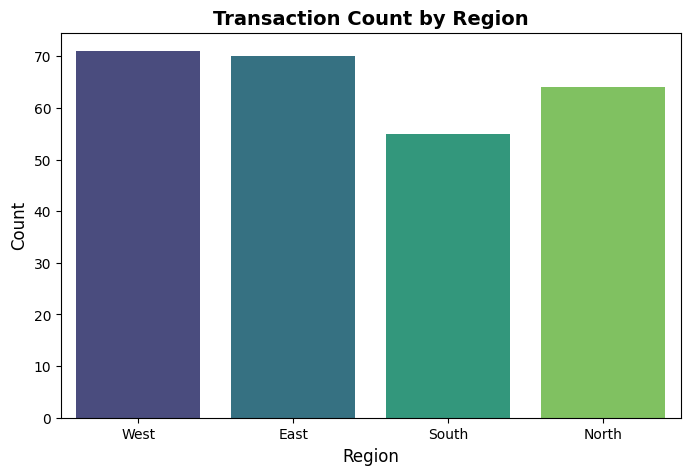

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='region', palette='viridis', order=['West', 'East', 'South', 'North'])

plt.title('Transaction Count by Region', fontsize=14, fontweight='bold')
plt.xlabel('Region', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.show()

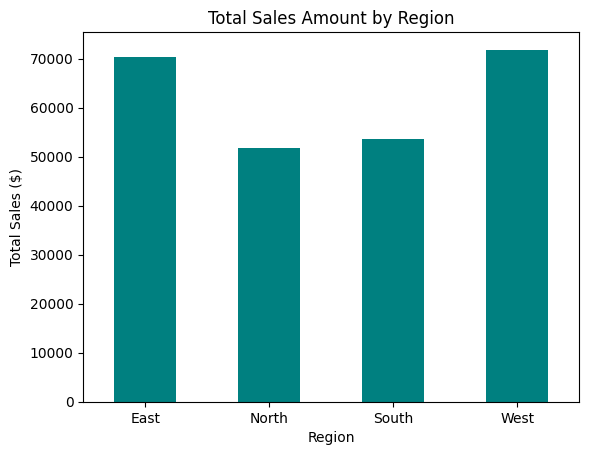

In [ ]:
import matplotlib.pyplot as plt

df.groupby('region')['sales_amount'].sum().plot(kind='bar', color='teal')

plt.title('Total Sales Amount by Region')
plt.xlabel('Region')
plt.ylabel('Total Sales ($)')
plt.xticks(rotation=0)
plt.show()

Bivariate,
pairplot,
heatmap,

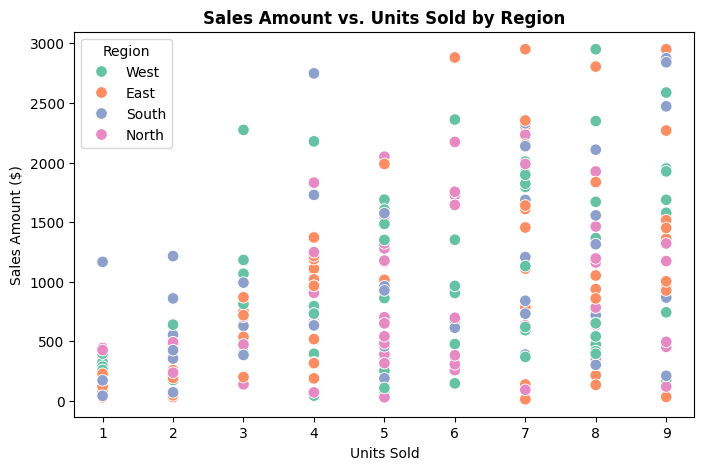

In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x='units_sold',
    y='sales_amount',
    hue='region',
    palette='Set2',
    s=70
)

plt.title('Sales Amount vs. Units Sold by Region', fontsize=12, fontweight='bold')
plt.xlabel('Units Sold')
plt.ylabel('Sales Amount ($)')
plt.legend(title='Region')
plt.show()

/tmp/ipykernel_1337/1516913870.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


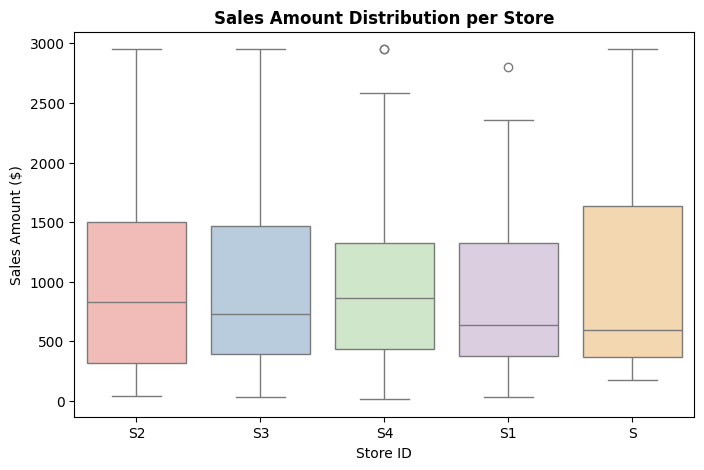

In [ ]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df,
    x='store_id',
    y='sales_amount',
    palette='Pastel1'
)

plt.title('Sales Amount Distribution per Store', fontsize=12, fontweight='bold')
plt.xlabel('Store ID')
plt.ylabel('Sales Amount ($)')
plt.show()

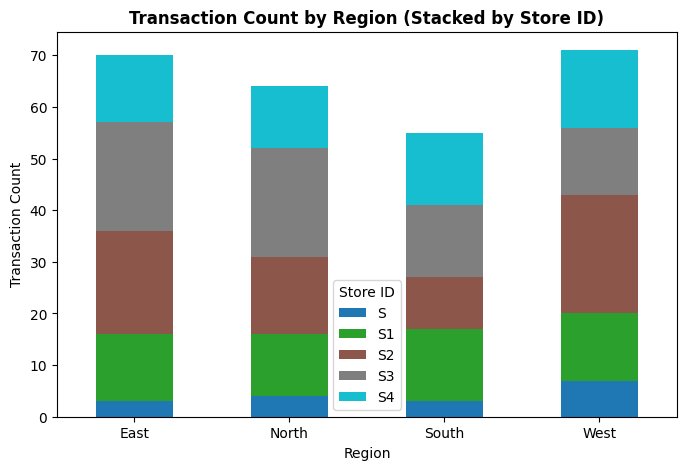

In [ ]:
region_store = pd.crosstab(df['region'], df['store_id'])


region_store.plot(kind='bar', stacked=True, figsize=(8, 5), colormap='tab10')

plt.title('Transaction Count by Region (Stacked by Store ID)', fontsize=12, fontweight='bold')
plt.xlabel('Region')
plt.ylabel('Transaction Count')
plt.xticks(rotation=0)
plt.legend(title='Store ID')
plt.show()

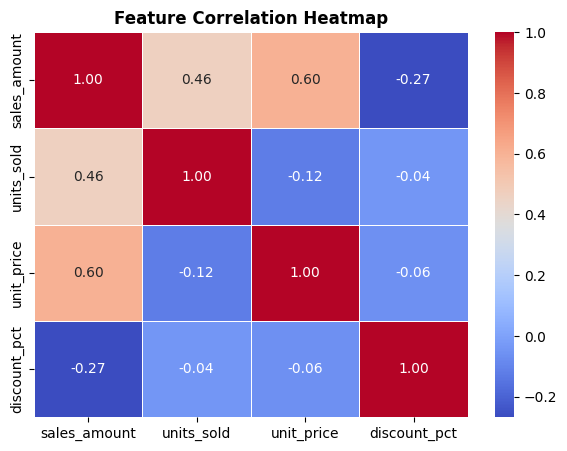

In [ ]:
plt.figure(figsize=(7, 5))

num_cols = ['sales_amount', 'units_sold', 'unit_price', 'discount_pct']
corr_matrix = df[num_cols].corr()


sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)

plt.title('Feature Correlation Heatmap', fontsize=12, fontweight='bold')
plt.show()

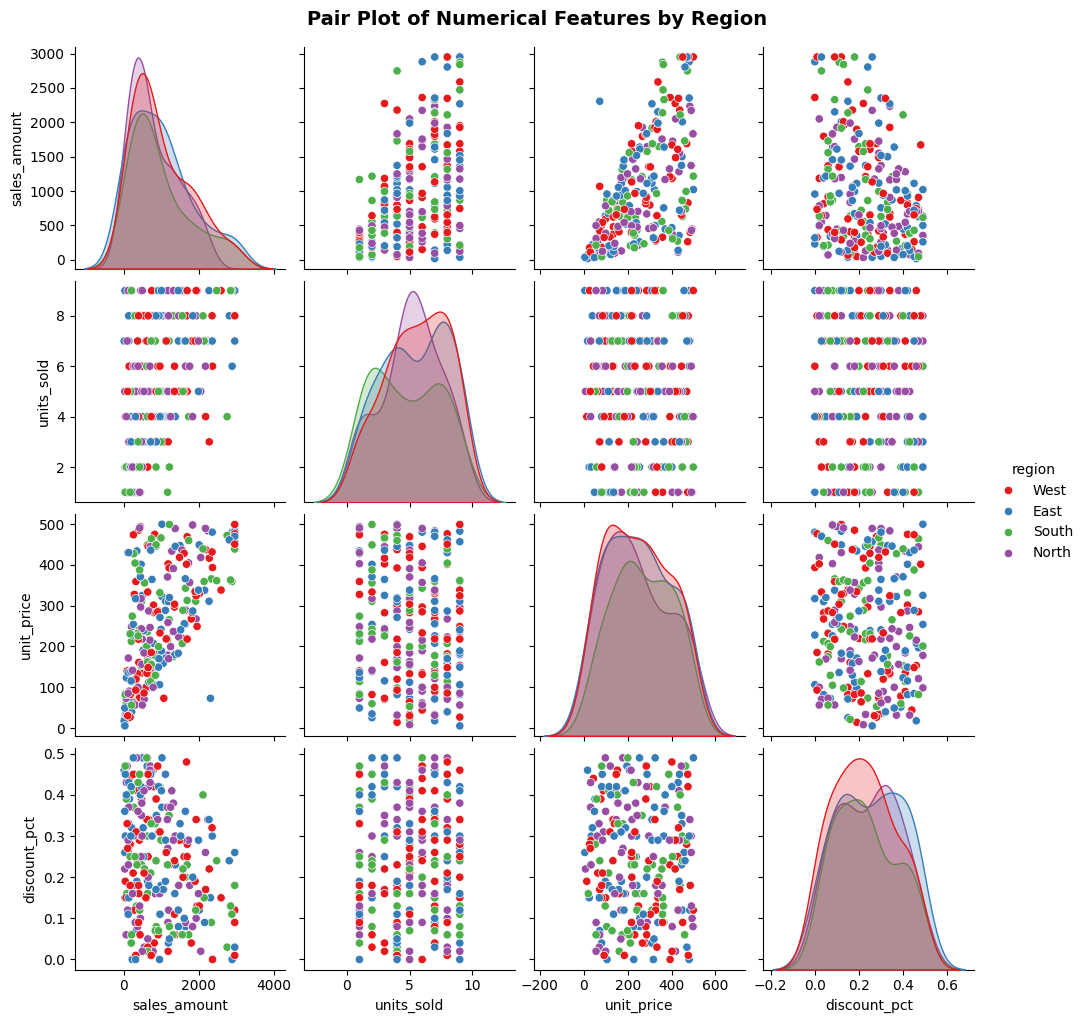

In [ ]:
sns.pairplot(
    df,
    vars=['sales_amount', 'units_sold', 'unit_price', 'discount_pct'],
    hue='region',
    palette='Set1',
    diag_kind='kde'
)

plt.suptitle('Pair Plot of Numerical Features by Region', y=1.02, fontsize=14, fontweight='bold')
plt.show()

REPORT:
1. Preprocessing Summary
Duplicates Removed: Dropped duplicate product ID columns (product_id.1, product_id.2, product_id.3).

Missing Data Imputed:

Replaced missing numerical values (sales_amount, units_sold, unit_price, discount_pct) with column medians.

Filled missing store_id values using the mode (S1) and forward-filled date gaps (ffill).

Autogenerated missing sequential transaction_ids and mapped missing product_ids by store mode.

Cleaning & Standardizing: Standardized typos in region (West, East, South, North) and store_id (S1–S4).

Outliers Capped: Capped sales_amount extreme values using IQR clipping (.clip()).

2. Key EDA Findings
Balanced Regional Volume: Transactions are evenly distributed across all four regions (West, East, South, and North).

Store Contribution: Store S1 leads in total transaction volume, followed closely by S2, S3, and S4.

Revenue Drivers: Total sales_amount is primarily driven by higher unit_price rather than units_sold (which remains stable between 1–9 items per order).

Correlation: Numerical features show standard linear relationships (high correlation between volume/price and total sales amount) with clean distributions ready for modeling.